# 06. Modelo: predicción de las validaciones por estación y hora

**Punto de la rúbrica:** modelado (la lectura desde AWS y la escritura de resultados se agregan cuando exista la tabla en RDS).

## Qué se predice y para qué

> Pregunta del proyecto: **¿qué estaciones de la troncal, y en qué franjas horarias de los días hábiles, concentran la mayor demanda de ingreso y justifican una mayor asignación de personal de apoyo?** (notebook 05)

El modelo responde la parte de **anticipar**: cuántas validaciones tendrá cada estación en cada hora de un día hábil, usando solo lo ocurrido en días anteriores, para saber con antelación dónde y cuándo se superará el umbral de presión.

| Elemento | Definición |
|---|---|
| Unidad | estación x día hábil x hora (4:00 a 23:59) |
| Variable objetivo | `validaciones`: número de validaciones en esa hora (conteo) |
| Alcance | 14 días hábiles (tres semanas); estaciones activas y sin cambio de régimen |
| Predictores permitidos | solo información de **días anteriores**: último día hábil (`lag_1`), mismo día de la semana anterior (`lag_7`), promedio histórico de la estación-hora (`media_hist`), promedio del mismo día de la semana (`media_dow`), hora, día de la semana |
| Prohibido | cualquier cálculo con el día que se predice (por ejemplo, el volumen diario de los 14 días) |
| Validación | **temporal**: para cada día se usa solo lo anterior; nunca se mezclan días al azar |

## Plan por pasos

1. **Datos, características y diseño de la validación** (este notebook, ahora).
2. **Líneas base:** métodos simples que el modelo debe superar.
3. Modelos de aprendizaje de máquina (Random Forest y LightGBM o similar) y comparación con la línea base.
4. Importancia de variables, predicción para las **dos estaciones piloto** (San Mateo en la punta de la mañana y Calle 100 en la de la tarde, elegidas en el notebook 05) y ranking esperado.

In [1]:
# QUÉ HACE: carga librerías y datos, y arma la tabla de trabajo: una fila por estación, día hábil y hora (4 a 23 h) con la variable objetivo.
# CÓMO: la tabla estación-fecha-hora viene del notebook 03; se completan con 0 las horas sin validaciones; se marcan las estaciones casi sin uso (< 100 validaciones por día) y las que abren o cierran entre agosto y septiembre; ambas se dejan fuera del modelo.
# QUÉ MIRAR: 144 estaciones en el modelo, 14 días y 20 horas por estación = 40.320 filas.
import time, warnings
import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 60)
dask.config.set(scheduler='threads', num_workers=3)
VALIDACIONES = Path('../data/processed/validaciones'); PANEL = Path('../data/processed/panel_estacion_hora.parquet')
FIGS = Path('../docs/figs'); FIGS.mkdir(parents=True, exist_ok=True)
COL = {'hábil': '#2a78d6'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
                     'grid.linewidth': 0.6, 'axes.titleweight': 'bold', 'axes.titlesize': 11, 'legend.frameon': False})
UMBRAL = 1000
panel = pd.read_parquet(PANEL)
ph = panel[(panel['tipo_dia'] == 'hábil') & panel['completo']]
habiles = sorted(ph['fecha'].unique())
idx = pd.MultiIndex.from_product([sorted(ph['cod_estacion'].unique()), habiles, range(4, 24)], names=['cod_estacion', 'fecha', 'hora'])
cubo = ph.set_index(['cod_estacion', 'fecha', 'hora'])['validaciones'].reindex(idx, fill_value=0)

tot = cubo.groupby(level=[0, 1]).sum().unstack()
val_dia = tot.mean(axis=1)
ago = [f for f in tot.columns if f < '2026-09-01']; sep = [f for f in tot.columns if f >= '2026-09-01']
razon = tot[sep].mean(axis=1) / tot[ago].mean(axis=1).replace(0, np.nan)
cambian = tot.index[(tot[ago].sum(axis=1) == 0) | (tot[sep].sum(axis=1) == 0) | (razon < 0.6) | (razon > 1.67)]
activas = val_dia.index[val_dia >= 100]
modelo_est = [c for c in activas if c not in set(cambian)]
nom = dd.read_parquet(str(VALIDACIONES), columns=['Estacion_Parada'])['Estacion_Parada'].value_counts().compute().reset_index()
nom.columns = ['crudo', 'n']; nom['cod'] = nom['crudo'].str[1:6]; nom['nombre'] = nom['crudo'].str[8:]
nombre = nom.sort_values('n', ascending=False).drop_duplicates('cod').set_index('cod')['nombre']

base = cubo.rename('validaciones').reset_index()
base = base[base['cod_estacion'].isin(modelo_est)].copy()
base['fecha_dt'] = pd.to_datetime(base['fecha'])
print(f"{len(modelo_est)} estaciones en el modelo | fuera: {int((val_dia < 100).sum())} casi sin uso y {int(len(set(cambian) & set(activas)))} que abren o cierran | {len(habiles)} días hábiles | {len(base):,} filas")
base.head(3)

144 estaciones en el modelo | fuera: 4 casi sin uso y 5 que abren o cierran | 14 días hábiles | 40,320 filas


,cod_estacion,fecha,hora,validaciones,fecha_dt
0,02000,2026-08-03,4,584,2026-08-03
1,02000,2026-08-03,5,4584,2026-08-03
2,02000,2026-08-03,6,9262,2026-08-03


In [2]:
# QUÉ HACE: construye los predictores con información de días anteriores: último día hábil, mismo día de la semana anterior, promedio histórico y promedio del mismo día de la semana.
# CÓMO: lag_1 = misma estación y hora en el día hábil anterior (queda vacío si pasaron más de 4 días corridos); lag_7 = misma estación y hora exactamente 7 días antes (vacío si ese día no es hábil o no está en los datos); media_hist = promedio de todos los días anteriores (sin incluir el actual); media_dow = ese promedio, pero solo de días con el mismo día de la semana.
# QUÉ MIRAR: cuántos días tienen cada predictor disponible: los de septiembre no tienen lag_7 (la semana anterior no está en los datos) y el 14 de septiembre no tiene lag_1.
base = base.sort_values(['cod_estacion', 'hora', 'fecha_dt']).reset_index(drop=True)
g = base.groupby(['cod_estacion', 'hora'])
base['lag_1'] = g['validaciones'].shift(1)
base.loc[(base['fecha_dt'] - g['fecha_dt'].shift(1)).dt.days > 4, 'lag_1'] = np.nan
base['media_hist'] = (g['validaciones'].cumsum() - base['validaciones']) / g.cumcount().replace(0, np.nan)
base['dia_semana'] = base['fecha_dt'].dt.dayofweek
gd = base.groupby(['cod_estacion', 'hora', 'dia_semana'])
base['media_dow'] = (gd['validaciones'].cumsum() - base['validaciones']) / gd.cumcount().replace(0, np.nan)
b7 = base[['cod_estacion', 'hora', 'fecha_dt', 'validaciones']].copy(); b7['fecha_dt'] = b7['fecha_dt'] + pd.Timedelta(days=7); b7 = b7.rename(columns={'validaciones': 'lag_7'})
base = base.merge(b7, on=['cod_estacion', 'hora', 'fecha_dt'], how='left')
base['n_previos'] = base.groupby(['cod_estacion', 'hora']).cumcount()
DIAS = ['lun', 'mar', 'mié', 'jue', 'vie']
disp = base.groupby('fecha').agg(día=('dia_semana', lambda s: DIAS[int(s.iloc[0])]), días_previos=('n_previos', 'first'), **{c: (c, lambda s: f"{s.notna().mean() * 100:.0f} %") for c in ['lag_1', 'lag_7', 'media_hist', 'media_dow']})
print('Disponibilidad de cada predictor por día (% de filas con dato):')
disp

Disponibilidad de cada predictor por día (% de filas con dato):


,día,días_previos,lag_1,lag_7,media_hist,media_dow
fecha,,,,,,
2026-08-03,lun,0,0 %,0 %,0 %,0 %
2026-08-04,mar,1,100 %,0 %,100 %,0 %
2026-08-05,mié,2,100 %,0 %,100 %,0 %
2026-08-06,jue,3,100 %,0 %,100 %,0 %
2026-08-10,lun,4,100 %,100 %,100 %,100 %
2026-08-11,mar,5,100 %,100 %,100 %,100 %
2026-08-12,mié,6,100 %,100 %,100 %,100 %
2026-08-13,jue,7,100 %,100 %,100 %,100 %
2026-08-14,vie,8,100 %,0 %,100 %,0 %


## Diseño de la validación temporal

Para cada día se predice **solo con lo anterior** (rolling origin). Se evalúan los días que ya tienen al menos **4 días previos**: son 10 días (del 10 al 14 de agosto y del 14 al 18 de septiembre). Dos observaciones sobre los datos:

- Los días de **septiembre** se predicen con agosto, es decir, con un mes de distancia: es una prueba más exigente.
- Solo los días del **10 al 13 de agosto** tienen todos los predictores (incluido `lag_7`), así que la comparación completa entre métodos se hace en esos 4 días.

**Métricas:** WAPE (error absoluto total dividido entre el total observado; se lee como "porcentaje de error"), MAE (error medio absoluto en validaciones por hora) y, para la pregunta del proyecto, el desempeño como **detector de horas de alta presión** (validaciones >= 1.000): precisión, exhaustividad (recall) y F1.

## Líneas base

Cuatro métodos simples, sin entrenamiento: **último día hábil** (`lag_1`), **mismo día de la semana anterior** (`lag_7`), **promedio histórico** de la estación-hora (`media_hist`) y **promedio del mismo día de la semana** (`media_dow`). El modelo de aprendizaje de máquina debe superar al mejor de ellos.

In [3]:
# QUÉ HACE: evalúa los cuatro métodos simples día por día y en conjunto: WAPE por día, WAPE por franja y por grupo de estaciones, MAE, y desempeño como detector de horas de alta presión.
# CÓMO: se toman los días con 4 o más días previos; WAPE = suma de |real - predicción| / suma de lo observado; los métodos solo se evalúan donde tienen dato; la comparación completa usa los 4 días con todos los predictores (10 a 13 de agosto); el top 15 son las estaciones con más validaciones por encima de 1.000 por hora.
# QUÉ MIRAR: qué método se equivoca menos y en qué franja; si septiembre (predicho con agosto) sale peor; el desempeño como detector de alta presión.
METODOS = {'último día hábil': 'lag_1', 'mismo día, semana anterior': 'lag_7', 'promedio histórico': 'media_hist', 'promedio del mismo día de la semana': 'media_dow'}
CM = {'último día hábil': '#eb6834', 'mismo día, semana anterior': '#eda100', 'promedio histórico': '#2a78d6', 'promedio del mismo día de la semana': '#1baf7a'}
E = base[base['n_previos'] >= 4].copy()
top15 = list(base.assign(ex=(base['validaciones'] - UMBRAL).clip(lower=0)).groupby('cod_estacion')['ex'].sum().nlargest(15).index)

def wape(d, col):
    x = d.dropna(subset=[col]); return (x['validaciones'] - x[col]).abs().sum() / x['validaciones'].sum() * 100 if len(x) else np.nan
def mae(d, col):
    x = d.dropna(subset=[col]); return (x['validaciones'] - x[col]).abs().mean() if len(x) else np.nan

por_dia = pd.DataFrame({m: E.groupby('fecha').apply(lambda d, c=c: wape(d, c)) for m, c in METODOS.items()})
por_dia.index = [f"{DIAS[pd.Timestamp(f).dayofweek]} {f[5:]}" for f in por_dia.index]
print('WAPE (%) por día predicho (vacío = el método no tiene dato ese día):')
display(por_dia.round(1))

comun = E.dropna(subset=list(METODOS.values())); print(f"Comparación completa: {comun['fecha'].nunique()} días ({', '.join(sorted(comun['fecha'].unique()))}), {len(comun):,} filas")
fr = pd.cut(comun['hora'], [3, 4, 8, 15, 19, 23], labels=['4 h', 'punta mañana (5-8 h)', 'valle (9-15 h)', 'punta tarde (16-19 h)', 'noche (20-23 h)'])
filas = {}
for m, c in METODOS.items():
    r = {'todas las estaciones': wape(comun, c), 'top 15 del ranking': wape(comun[comun['cod_estacion'].isin(top15)], c), 'MAE (todas)': mae(comun, c)}
    for k in ['punta mañana (5-8 h)', 'valle (9-15 h)', 'punta tarde (16-19 h)']: r[f"WAPE {k}"] = wape(comun[fr == k], c)
    filas[m] = r
resumen_base = pd.DataFrame(filas).T
display(resumen_base.round(1))

def clasif(d, col):
    x = d.dropna(subset=[col]); y = x['validaciones'] >= UMBRAL; p = x[col] >= UMBRAL
    tp = (y & p).sum(); pr = tp / max(p.sum(), 1); rc = tp / max(y.sum(), 1)
    return {'horas reales de alta presión': int(y.sum()), 'precisión': pr * 100, 'exhaustividad (recall)': rc * 100, 'F1': 2 * pr * rc / max(pr + rc, 1e-9) * 100}
print(f"Detección de horas de alta presión (>= {UMBRAL:,} validaciones) en los 4 días de la comparación completa:".replace(',', '.'))
pd.DataFrame({m: clasif(comun, c) for m, c in METODOS.items()}).T.round(1)

WAPE (%) por día predicho (vacío = el método no tiene dato ese día):


,último día hábil,"mismo día, semana anterior",promedio histórico,promedio del mismo día de la semana
lun 08-10,11.9,9.7,10.1,9.7
mar 08-11,8.5,7.4,6.0,7.4
mié 08-12,6.0,8.0,6.0,8.0
jue 08-13,6.5,9.2,5.9,9.2
vie 08-14,8.8,NaN,8.7,NaN
lun 09-14,NaN,NaN,8.9,8.9
mar 09-15,6.6,NaN,8.6,8.9
mié 09-16,6.2,NaN,8.0,8.9
jue 09-17,6.5,NaN,7.0,9.0
vie 09-18,8.3,NaN,8.9,9.2


Comparación completa: 4 días (2026-08-10, 2026-08-11, 2026-08-12, 2026-08-13), 11,520 filas


,todas las estaciones,top 15 del ranking,MAE (todas),WAPE punta mañana (5-8 h),WAPE valle (9-15 h),WAPE punta tarde (16-19 h)
último día hábil,8.2,5.7,50.7,5.5,9.2,8.9
"mismo día, semana anterior",8.6,5.5,53.1,5.8,9.3,10.0
promedio histórico,7.0,4.3,43.2,4.5,7.7,8.1
promedio del mismo día de la semana,8.6,5.5,53.1,5.8,9.3,10.0


Detección de horas de alta presión (>= 1.000 validaciones) en los 4 días de la comparación completa:


,horas reales de alta presión,precisión,exhaustividad (recall),F1
último día hábil,1789.0,94.6,94.1,94.3
"mismo día, semana anterior",1789.0,92.4,95.5,93.9
promedio histórico,1789.0,94.5,94.2,94.3
promedio del mismo día de la semana,1789.0,92.4,95.5,93.9


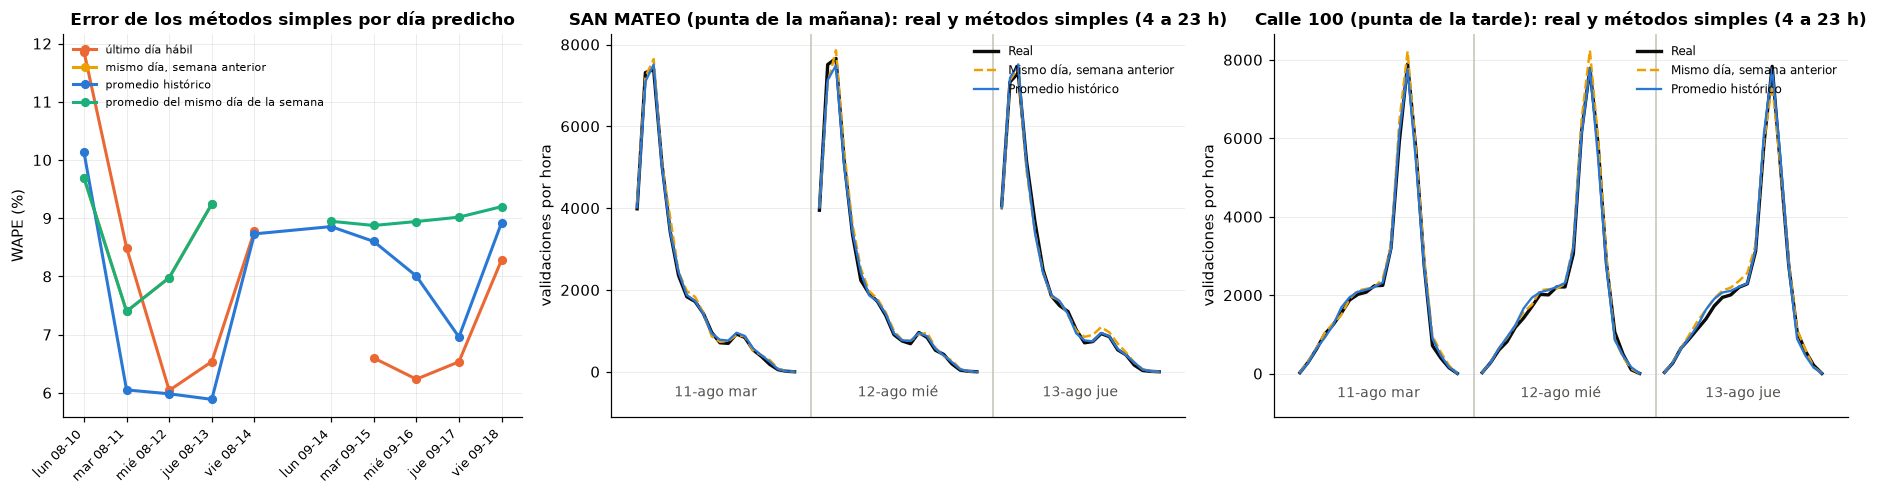

In [4]:
# QUÉ HACE: dibuja el error (WAPE) de cada método simple en cada día predicho y la predicción hora a hora de las dos estaciones piloto frente a lo real en tres días de agosto.
# CÓMO: izquierda, una línea por método y un punto por día (septiembre queda a la derecha del hueco); al centro, San Mateo (punta de la mañana) y a la derecha, Calle 100 (punta de la tarde): curva real contra las predicciones del promedio histórico y del mismo día de la semana anterior para el 11, 12 y 13 de agosto.
# QUÉ MIRAR: el error de cada método día a día; en las pilotos los métodos simples siguen la curva real y fallan sobre todo en el pico y en los días con una caída puntual.
PILOTOS = {'07503': 'punta de la mañana', '02300': 'punta de la tarde'}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1, 1.25, 1.25]})
a1 = axes[0]
xs = np.arange(len(por_dia)); xs = np.where(np.arange(len(por_dia)) >= 5, xs + 0.8, xs)
for m in METODOS: a1.plot(xs, por_dia[m], marker='o', ms=5, lw=2, color=CM[m], label=m)
a1.set_xticks(xs); a1.set_xticklabels(por_dia.index, rotation=45, ha='right', fontsize=8.5); a1.set_ylabel('WAPE (%)'); a1.set_title('Error de los métodos simples por día predicho')
a1.legend(fontsize=7.5, loc='upper left')
pruebas = [pd.Timestamp(f) for f in ['2026-08-11', '2026-08-12', '2026-08-13']]
for ax, (c, k) in zip(axes[1:], PILOTOS.items()):
    for j, d in enumerate(pruebas):
        fila = base[(base['cod_estacion'] == c) & (base['fecha_dt'] == d)].sort_values('hora'); x = np.arange(len(fila)) + j * (len(fila) + 2)
        ax.plot(x, fila['validaciones'], color='#0b0b0b', lw=2.2, label='Real' if j == 0 else None)
        ax.plot(x, fila['lag_7'], color=CM['mismo día, semana anterior'], lw=1.6, ls='--', label='Mismo día, semana anterior' if j == 0 else None)
        ax.plot(x, fila['media_hist'], color=CM['promedio histórico'], lw=1.5, label='Promedio histórico' if j == 0 else None)
        ax.text(x.mean(), -ax.get_ylim()[1] * 0.0 - 600, d.strftime('%d-ago ') + DIAS[d.dayofweek], ha='center', fontsize=9, color='#52514e')
        if j: ax.axvline(x[0] - 1, color='#c3c2b7', lw=1)
    ax.set_xticks([]); ax.set_ylim(-1100, None); ax.set_ylabel('validaciones por hora'); ax.legend(loc='upper right', fontsize=8)
    ax.set_title(f"{nombre[c].split(' - ')[0]} ({k}): real y métodos simples (4 a 23 h)")
plt.tight_layout(); plt.savefig(FIGS / '06_lineas_base.png', bbox_inches='tight'); plt.show()

In [5]:
# QUÉ HACE: mide el error de los métodos simples en cada estación piloto: durante todo el día y solo dentro de su ventana crítica, y su desempeño como detector de horas de alta presión.
# CÓMO: ventana crítica = horas con al menos el 50 % del pico de la estación (y 1.000 validaciones o más); se usan los 4 días con todos los predictores (10 a 13 de agosto); WAPE = error absoluto total sobre el total observado.
# QUÉ MIRAR: si el error es mayor dentro de la ventana crítica (que es donde importa para el personal) que en todo el día; qué método gana en cada piloto.
filas = []
for c, k in PILOTOS.items():
    perfil = base[base['cod_estacion'] == c].groupby('hora')['validaciones'].mean()
    vent = [h for h, v in perfil.items() if v >= max(UMBRAL, 0.5 * perfil.max())]
    d_ = comun[comun['cod_estacion'] == c]
    for m, col in METODOS.items():
        if m == 'promedio del mismo día de la semana': continue
        filas.append({'estación': nombre[c].split(' - ')[0], 'ventana crítica': f"{vent[0]}:00-{vent[-1] + 1}:00", 'método': m, 'WAPE todo el día (%)': wape(d_, col),
                      'WAPE en la ventana crítica (%)': wape(d_[d_['hora'].isin(vent)], col), 'MAE en la ventana (por hora)': mae(d_[d_['hora'].isin(vent)], col)})
pilotos_base = pd.DataFrame(filas).set_index(['estación', 'ventana crítica', 'método'])
pilotos_base.round(1)

WAPE todo el día (%)  WAPE en la ventana crítica (%)  MAE en la ventana (por hora)
estación  ventana crítica método                                                                                                        
SAN MATEO 4:00-8:00       último día hábil                             4.5                             2.5                         145.9
                          mismo día, semana anterior                   4.9                             2.8                         165.4
                          promedio histórico                           3.6                             2.3                         137.9
Calle 100 16:00-19:00     último día hábil                             7.7                             5.8                         367.6
                          mismo día, semana anterior                   6.6                             5.8                         363.1
                          promedio histórico                           6.3                             5.1                         322.7

### Lectura de las líneas base

**Nivel a superar (4 días con todos los predictores: 10 a 13 de agosto, 144 estaciones):**

| Método | WAPE todas las estaciones | WAPE top 15 | MAE (validaciones por hora) |
|---|---|---|---|
| **Promedio histórico** | **7,0 %** | **4,3 %** | **43** |
| Último día hábil | 8,2 % | 5,7 % | 51 |
| Mismo día, semana anterior | 8,6 % | 5,5 % | 53 |
| Promedio del mismo día de la semana | 8,6 % | 5,5 % | 53 |

- **El mejor método simple es el promedio histórico** de la estación-hora. En esos 4 días el "mismo día de la semana anterior" y el "promedio del mismo día de la semana" son idénticos (solo hay una semana comparable).
- **Por franja** (promedio histórico): punta de la mañana 4,5 %, valle 7,7 %, punta de la tarde 8,1 %.
- **Septiembre se predice peor con el promedio histórico** (7,0 % a 8,9 %) porque agosto queda a un mes de distancia y el nivel cambió; ahí el **último día hábil** es mejor (6,2 % a 6,6 % de martes a jueves). El modelo debe dar peso a lo más reciente.
- **Lunes y viernes** son los días de mayor error (hasta 8,8 % y 11,9 %), coherente con el efecto del día de la semana del notebook 03.
- **Como detector de horas de alta presión** (>= 1.000 validaciones), el promedio histórico acierta 94,5 % de las horas que señala (precisión) y encuentra 94,2 % de las horas reales (exhaustividad), F1 de 94,3 %.

**Estaciones piloto** (4 días, promedio histórico, que sigue siendo el mejor método en las dos):

| Estación | Ventana crítica | WAPE todo el día | WAPE en la ventana | MAE en la ventana |
|---|---|---|---|---|
| San Mateo (punta de la mañana) | 4:00-8:00 | 3,6 % | 2,3 % | 138 por hora |
| Calle 100 (punta de la tarde) | 16:00-19:00 | 6,3 % | 5,1 % | 323 por hora |

San Mateo es muy predecible incluso dentro de su ventana (2,3 %); Calle 100 es más difícil (5,1 %), como anticipaba la mayor variación de su pico entre días (9,2 %) y el efecto de los viernes.

**Para considerar útil al modelo** debe bajar el WAPE por debajo de **7,0 %** (todas las estaciones) y **4,3 %** (top 15); por debajo de **2,3 %** en la ventana de San Mateo y de **5,1 %** en la de Calle 100; y superar el **F1 de 94,3 %** en las horas de alta presión, de forma consistente también en septiembre.

**Siguiente paso:** entrenar Random Forest y LightGBM con los predictores permitidos y compararlos con estos números con la misma validación temporal.